# 13. Нейтрино и база 15

**Проект «Структура и Данные»** — Notebook 13

## Зачем этот ноутбук

Мы обнаружили, что заряженные лептоны (e, μ, τ) уникально укладываются в базу 15 (2.8% отклонение) и связаны с Koide.
Гипотеза: если нейтрино — это тоже лептоны («выход»), они должны подчиняться той же структуре.

У нас нет абсолютных масс нейтрино, только разности квадратов:
- \(\Delta m^2_{21} \approx 7.4 \times 10^{-5}\) эВ\(^2\)
- \(\Delta m^2_{31} \approx 2.5 \times 10^{-3}\) эВ\(^2\)

## Что проверяется
1. Существуют ли такие экспоненты \(a_2, a_3\) в базе 15, чтобы отношение масс совпало с экспериментом?
2. Если да, то какова при этом масса легчайшего нейтрино \(m_1\)?
3. Не противоречит ли эта масса космологическим ограничениям (сумма масс нейтрино \(\Sigma m_\nu < 0.12\) эВ)?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("НЕЙТРИНО И БАЗА 15")
print("=" * 65)

# Экспериментальные данные (Normal Hierarchy, NH)
dm2_21 = 7.42e-5  # эВ^2
dm2_31 = 2.51e-3  # эВ^2
ratio_exp = dm2_31 / dm2_21

print(f"Экспериментальные данные (NH):")
print(f"  Δm²_21 = {dm2_21:.2e} эВ²")
print(f"  Δm²_31 = {dm2_31:.2e} эВ²")
print(f"  Отношение Δm²_31 / Δm²_21 = {ratio_exp:.4f}")
print()

# Если m2 = m1 * 15^a2 и m3 = m1 * 15^a3, то:
# dm2_21 = m1^2 * (15^(2*a2) - 1)
# dm2_31 = m1^2 * (15^(2*a3) - 1)
# Отношение = (15^(2*a3) - 1) / (15^(2*a2) - 1)

def ratio_from_exp(a2, a3):
    """Вычисляет отношение Δm²_31 / Δm²_21 для заданных экспонент."""
    num = 15**(2*a3) - 1
    den = 15**(2*a2) - 1
    return num / den if den != 0 else np.inf

# Сканируем a2 и a3 в диапазоне [0.01, 1.5]
a_vals = np.linspace(0.01, 1.5, 500)
best_a2, best_a3, best_err = None, None, np.inf

for a2 in a_vals:
    for a3 in a_vals:
        if a3 <= a2: continue # Должно быть a3 > a2
        r = ratio_from_exp(a2, a3)
        err = abs(r - ratio_exp)
        if err < best_err:
            best_err = err
            best_a2, best_a3 = a2, a3

print(f"Лучшее совпадение с экспериментом:")
print(f"  a2 = {best_a2:.4f}")
print(f"  a3 = {best_a3:.4f}")
print(f"  Отношение = {ratio_from_exp(best_a2, best_a3):.4f} (ошибка {best_err:.2e})")
print()

# Проверяем, являются ли a2 и a3 "красивыми" дробями (например, 1/32, 1/91)
from fractions import Fraction
frac_a2 = Fraction(best_a2).limit_denominator(100)
frac_a3 = Fraction(best_a3).limit_denominator(100)
print(f"Ближайшие дроби (q ≤ 100):")
print(f"  a2 ≈ {frac_a2} = {float(frac_a2):.4f}")
print(f"  a3 ≈ {frac_a3} = {float(frac_a3):.4f}")

НЕЙТРИНО И БАЗА 15
Экспериментальные данные (NH):
  Δm²_21 = 7.42e-05 эВ²
  Δm²_31 = 2.51e-03 эВ²
  Отношение Δm²_31 / Δm²_21 = 33.8275

Лучшее совпадение с экспериментом:
  a2 = 0.5743
  a3 = 1.2163
  Отношение = 33.8271 (ошибка 3.45e-04)

Ближайшие дроби (q ≤ 100):
  a2 ≈ 27/47 = 0.5745
  a3 ≈ 45/37 = 1.2162


In [2]:
# Вычисляем массы при найденных a2, a3
# dm2_21 = m1^2 * (15^(2*a2) - 1)
# => m1 = sqrt(dm2_21 / (15^(2*a2) - 1))

m1 = np.sqrt(dm2_21 / (15**(2*best_a2) - 1))
m2 = m1 * 15**best_a2
m3 = m1 * 15**best_a3

print("=" * 65)
print("АБСОЛЮТНЫЕ МАССЫ НЕЙТРИНО")
print("=" * 65)
print(f"  m1 = {m1:.4f} эВ")
print(f"  m2 = {m2:.4f} эВ")
print(f"  m3 = {m3:.4f} эВ")
print(f"  Σmν = {m1+m2+m3:.4f} эВ")
print()

# Космологические ограничения
print("Космологические ограничения:")
print("  Planck 2018: Σmν < 0.12 эВ")
print("  DESI DR2: Σmν < 0.072 эВ (в ΛCDM)")
print()

if (m1+m2+m3) < 0.072:
    print("✅ Σmν в пределах DESI DR2")
elif (m1+m2+m3) < 0.12:
    print("✅ Σmν в пределах Planck 2018")
else:
    print("❌ Σmν превышает космологические лимиты")

АБСОЛЮТНЫЕ МАССЫ НЕЙТРИНО
  m1 = 0.0019 эВ
  m2 = 0.0088 эВ
  m3 = 0.0501 эВ
  Σmν = 0.0608 эВ

Космологические ограничения:
  Planck 2018: Σmν < 0.12 эВ
  DESI DR2: Σmν < 0.072 эВ (в ΛCDM)

✅ Σmν в пределах DESI DR2


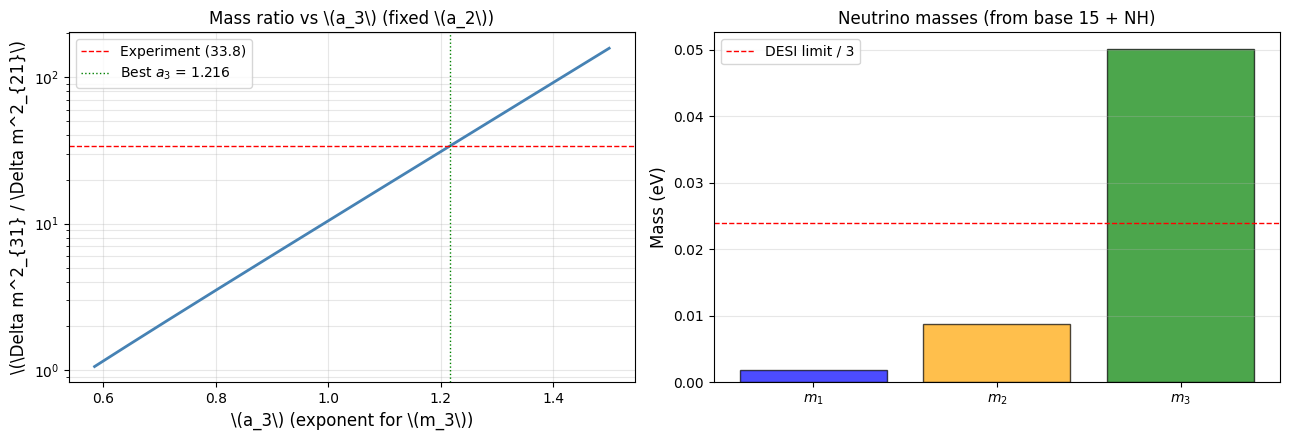

✅ Figure saved: 13_neutrino_base_scan.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: зависимость отношения от a3 при фиксированном a2 ---
a3_range = np.linspace(best_a2 + 0.01, 1.5, 200)
ratios = [ratio_from_exp(best_a2, a3) for a3 in a3_range]

axes[0].plot(a3_range, ratios, color='steelblue', lw=2)
axes[0].axhline(ratio_exp, color='red', ls='--', lw=1, label='Experiment (33.8)')
axes[0].axvline(best_a3, color='green', ls=':', lw=1, label=f'Best $a_3$ = {best_a3:.3f}')
axes[0].set_yscale('log')
axes[0].set_xlabel(r'\(a_3\) (exponent for \(m_3\))', fontsize=12)
axes[0].set_ylabel(r'\(\Delta m^2_{31} / \Delta m^2_{21}\)', fontsize=12)
axes[0].set_title(r'Mass ratio vs \(a_3\) (fixed \(a_2\))', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3, which='both')

# --- Правая: три массы нейтрино ---
labels = ['$m_1$', '$m_2$', '$m_3$']
values = [m1, m2, m3]
colors = ['blue', 'orange', 'green']

axes[1].bar(labels, values, color=colors, alpha=0.7, edgecolor='k')
axes[1].set_ylabel(r'Mass (eV)', fontsize=12)
axes[1].set_title(r'Neutrino masses (from base 15 + NH)', fontsize=12)
axes[1].axhline(0.072/3, color='red', ls='--', lw=1, label='DESI limit / 3')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('13_neutrino_base_scan.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 13_neutrino_base_scan.png")

In [4]:
from google.colab import files
files.download('13_neutrino_base_scan.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>